Q1. Student Performance and Correlation Analysis
A college wants to identify which academic factors have the strongest relationships with examination marks.

import pandas as pd

df = pd.DataFrame({
    "Study_Hours": [2, 3, 4, 5, 6, 7, 8, 9, 3, 6, 8, 4],
    "Attendance": [55, 60, 65, 70, 75, 80, 85, 95, 62, 78, 90, 68],
    "Assignments": [3, 4, 5, 5, 6, 7, 8, 10, 4, 7, 9, 5],
    "Sleep_Hours": [9, 8, 8, 7, 7, 6, 6, 5, 9, 7, 5, 8],
    "Marks": [40, 45, 50, 58, 65, 72, 78, 95, 43, 70, 90, 52]
})
(a) Calculate the Pearson correlation matrix and create an annotated heatmap. Rank all four features by their absolute correlation with Marks, identify the strongest positive and negative relationships, and explain what the coefficients indicate.



Correlation Matrix:
             Study_Hours  Attendance  Assignments  Sleep_Hours  Marks
Study_Hours        1.000       0.990        0.977       -0.968  0.981
Attendance         0.990       1.000        0.993       -0.962  0.993
Assignments        0.977       0.993        1.000       -0.952  0.991
Sleep_Hours       -0.968      -0.962       -0.952        1.000 -0.974
Marks              0.981       0.993        0.991       -0.974  1.000


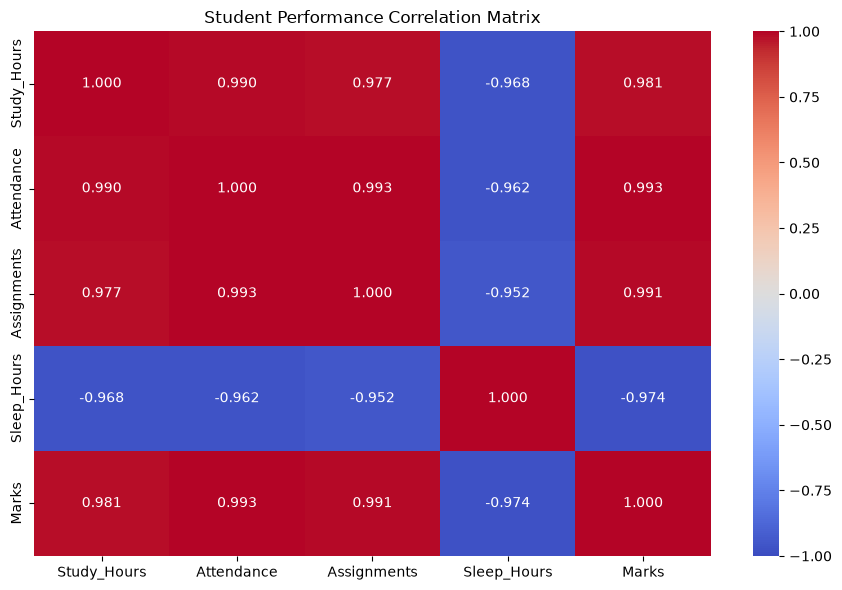


Feature Ranking by Absolute Correlation with Marks:
Attendance     0.9930
Assignments    0.9907
Study_Hours    0.9815
Sleep_Hours   -0.9738
Name: Marks, dtype: float64

Strongest Positive Relationship: Attendance 0.993
Strongest Negative Relationship: Sleep_Hours -0.9738


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Study_Hours": [2, 3, 4, 5, 6, 7, 8, 9, 3, 6, 8, 4],
    "Attendance": [55, 60, 65, 70, 75, 80, 85, 95, 62, 78, 90, 68],
    "Assignments": [3, 4, 5, 5, 6, 7, 8, 10, 4, 7, 9, 5],
    "Sleep_Hours": [9, 8, 8, 7, 7, 6, 6, 5, 9, 7, 5, 8],
    "Marks": [40, 45, 50, 58, 65, 72, 78, 95, 43, 70, 90, 52]
})

corr = df.corr()

print("Correlation Matrix:")
print(corr.round(3))

plt.figure(figsize=(9, 6))
sns.heatmap(
    corr, annot=True, cmap="coolwarm",
    vmin=-1, vmax=1, fmt=".3f"
)
plt.title("Student Performance Correlation Matrix")
plt.tight_layout()
plt.show()

feature_corr = corr["Marks"].drop("Marks")
ranking = feature_corr.reindex(
    np.abs(feature_corr).sort_values(ascending=False).index
)

print("\nFeature Ranking by Absolute Correlation with Marks:")
print(ranking.round(4))

print("\nStrongest Positive Relationship:",
      feature_corr.idxmax(),
      round(feature_corr.max(), 4))

print("Strongest Negative Relationship:",
      feature_corr.idxmin(),
      round(feature_corr.min(), 4))


(b) Remove the student with the highest marks and recalculate the correlation matrix. Compare the feature-to-marks correlations before and after removal, and explain how a single observation can influence the results.

Student Removed:
Study_Hours     9
Attendance     95
Assignments    10
Sleep_Hours     5
Marks          95
Name: 7, dtype: int64

Correlation Matrix After Removing Student:
             Study_Hours  Attendance  Assignments  Sleep_Hours  Marks
Study_Hours        1.000       0.988        0.973       -0.959  0.977
Attendance         0.988       1.000        0.991       -0.953  0.990
Assignments        0.973       0.991        1.000       -0.943  0.987
Sleep_Hours       -0.959      -0.953       -0.943        1.000 -0.969
Marks              0.977       0.990        0.987       -0.969  1.000

Correlation Comparison:
             Before   After  Change
Study_Hours  0.9815  0.9771 -0.0044
Attendance   0.9930  0.9901 -0.0029
Assignments  0.9907  0.9871 -0.0036
Sleep_Hours -0.9738 -0.9692  0.0046


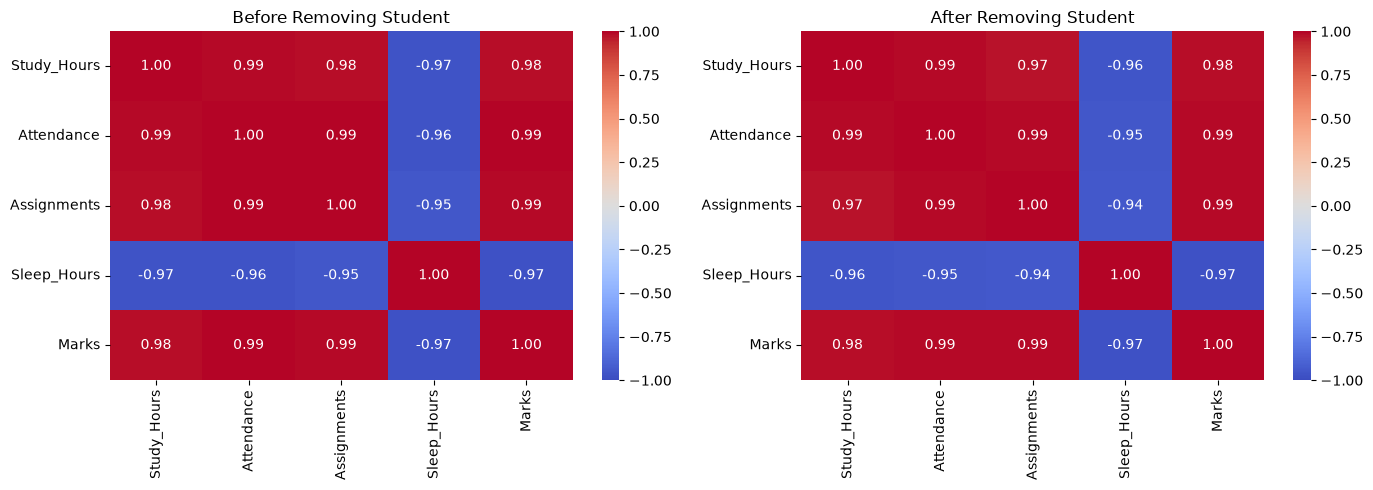

In [3]:
highest_index = df["Marks"].idxmax()
print("Student Removed:")
print(df.loc[highest_index])

df_new = df.drop(index=highest_index)

corr_new = df_new.corr()

print("\nCorrelation Matrix After Removing Student:")
print(corr_new.round(3))

before = corr["Marks"].drop("Marks")
after = corr_new["Marks"].drop("Marks")

comparison = pd.DataFrame({
    "Before": before,
    "After": after,
    "Change": after - before
})

print("\nCorrelation Comparison:")
print(comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    corr, annot=True, cmap="coolwarm",
    vmin=-1, vmax=1, fmt=".2f", ax=axes[0]
)
axes[0].set_title("Before Removing Student")

sns.heatmap(
    corr_new, annot=True, cmap="coolwarm",
    vmin=-1, vmax=1, fmt=".2f", ax=axes[1]
)
axes[1].set_title("After Removing Student")

plt.tight_layout()
plt.show()


Q2. Detecting Redundant Features in a Housing Dataset
A property company wants to investigate relationships among housing attributes before building a machine learning model.

import pandas as pd

df = pd.DataFrame({
    "Area_sqft": [800, 1000, 1200, 1400, 1600, 1800, 2000, 2200],
    "Area_sqm": [74.32, 92.90, 111.48, 130.06, 148.64, 167.22, 185.80, 204.38],
    "Bedrooms": [1, 2, 2, 3, 3, 3, 4, 4],
    "Age_Years": [25, 20, 18, 15, 12, 10, 8, 6],
    "Price_Lakhs": [25, 32, 38, 45, 52, 60, 68, 75]
})
(a) Generate a correlation matrix and heatmap. Programmatically identify unique feature pairs whose absolute correlation exceeds 0.90, excluding self-correlations and duplicate pairs. Explain why two highly correlated features may contain redundant information.



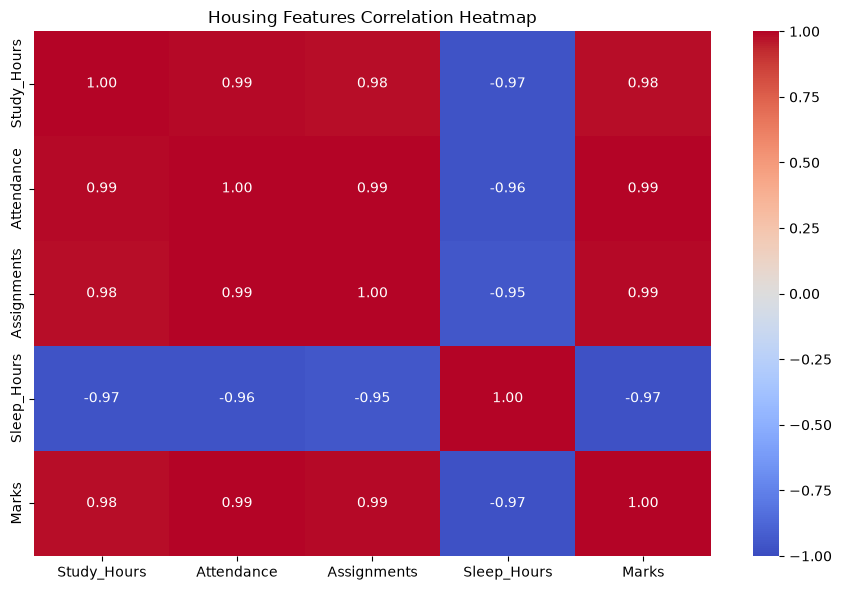


Highly Correlated Feature Pairs:
Study_Hours - Attendance: 0.9896
Study_Hours - Assignments: 0.9768
Study_Hours - Sleep_Hours: -0.9685
Study_Hours - Marks: 0.9815
Attendance - Assignments: 0.9931
Attendance - Sleep_Hours: -0.9621
Attendance - Marks: 0.9930
Assignments - Sleep_Hours: -0.9525
Assignments - Marks: 0.9907
Sleep_Hours - Marks: -0.9738


In [4]:
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, fmt=".2f")
plt.title("Housing Features Correlation Heatmap")
plt.tight_layout()
plt.show()

pairs = []

columns = corr.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        value = corr.iloc[i, j]

        if abs(value) > 0.90:
            pairs.append((columns[i], columns[j], value))

print("\nHighly Correlated Feature Pairs:")
for feature1, feature2, value in pairs:
    print(f"{feature1} - {feature2}: {value:.4f}")


(b) Create two feature sets, one containing both area measurements and another containing only Area_sqft. Compare the feature relationships and explain why correlation can help identify redundancy but cannot, by itself, prove that removing a feature will improve a model.

In [8]:
import pandas as pd
df = pd.DataFrame({
    "Area_sqft": [800, 1000, 1200, 1400, 1600, 1800, 2000, 2200],
    "Area_sqm": [74.32, 92.90, 111.48, 130.06, 148.64, 167.22, 185.80, 204.38],
    "Bedrooms": [1, 2, 2, 3, 3, 3, 4, 4],
    "Age_Years": [25, 20, 18, 15, 12, 10, 8, 6],
    "Price_Lakhs": [25, 32, 38, 45, 52, 60, 68, 75]
})

X_both = df[["Area_sqft", "Area_sqm"]]

X_one = df[["Area_sqft"]]

print("Both area features:", X_both.shape)
print("Only Area_sqft:", X_one.shape)

print("\nArea correlation:")
print(df["Area_sqft"].corr(df["Area_sqm"]))

print("\nCorrelation with Price:")
print("Area_sqft:", df["Area_sqft"].corr(df["Price_Lakhs"]))
print("Area_sqm:", df["Area_sqm"].corr(df["Price_Lakhs"]))


Both area features: (8, 2)
Only Area_sqft: (8, 1)

Area correlation:
1.0

Correlation with Price:
Area_sqft: 0.9991841879459334
Area_sqm: 0.9991841879459334


Q3. Customer Spending Analysis Using the Tips Dataset
Use Seaborn's built-in tips dataset to analyze restaurant bills and tips.

(a) Select total_bill, tip, and size. Calculate their Pearson correlation matrix and display an annotated heatmap. Identify the strongest relationship and support your interpretation with the calculated coefficients.



Correlation Matrix:
            total_bill    tip   size
total_bill       1.000  0.676  0.598
tip              0.676  1.000  0.489
size             0.598  0.489  1.000


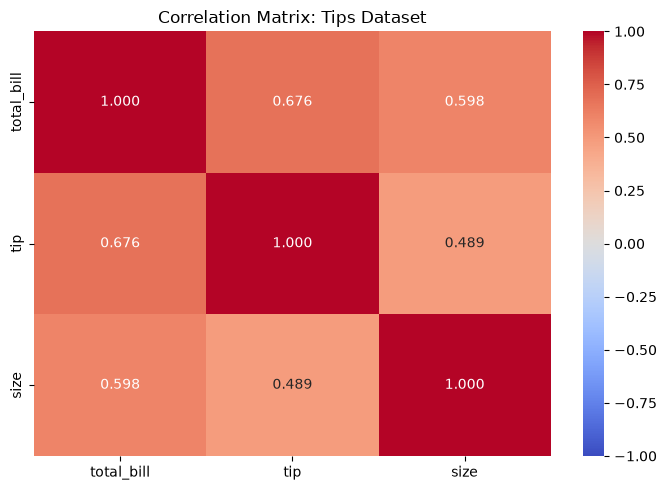


Strongest relationship:
('total_bill', 'tip')
Correlation: 0.6757341092113648


In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("tips")

data = df[["total_bill", "tip", "size"]]

corr = data.corr(method="pearson")

print("Correlation Matrix:")
print(corr.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".3f"
)
plt.title("Correlation Matrix: Tips Dataset")
plt.tight_layout()
plt.show()

pairs = corr.abs().where(
    ~pd.DataFrame(
        [[i == j for j in range(len(corr.columns))]
         for i in range(len(corr.columns))],
        index=corr.index,
        columns=corr.columns
    )
)

print("\nStrongest relationship:")
print(pairs.stack().idxmax())
print("Correlation:", corr.loc[
    pairs.stack().idxmax()[0], pairs.stack().idxmax()[1]
])


(b) Create a tip_percentage column using tip / total_bill * 100. Recalculate the correlation matrix and explain how this derived feature relates to total_bill and tip. Discuss why mathematical dependencies between variables can complicate the interpretation of correlation.

Updated Correlation Matrix:
                total_bill    tip   size  tip_percentage
total_bill           1.000  0.676  0.598          -0.339
tip                  0.676  1.000  0.489           0.342
size                 0.598  0.489  1.000          -0.143
tip_percentage      -0.339  0.342 -0.143           1.000


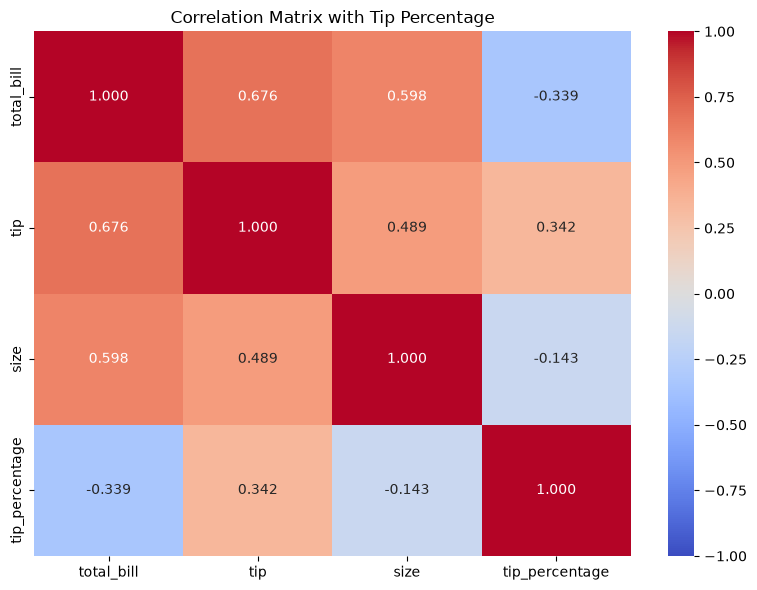


Correlation with Tip Percentage:
total_bill       -0.339
tip               0.342
size             -0.143
tip_percentage    1.000
Name: tip_percentage, dtype: float64


In [10]:
df["tip_percentage"] = df["tip"] / df["total_bill"] * 100

data_new = df[
    ["total_bill", "tip", "size", "tip_percentage"]
]

corr_new = data_new.corr()

print("Updated Correlation Matrix:")
print(corr_new.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_new,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".3f"
)
plt.title("Correlation Matrix with Tip Percentage")
plt.tight_layout()
plt.show()

print("\nCorrelation with Tip Percentage:")
print(corr_new["tip_percentage"].round(3))


Q4. Investigating the Effect of an Outlier
A marketing analyst investigates the relationship between advertising expenditure and sales.

import pandas as pd

df = pd.DataFrame({
    "Advertising": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55],
    "Sales": [20, 28, 35, 42, 50, 58, 65, 72, 80, 88]
})
(a) Calculate the correlation matrix and plot a heatmap. Add a new observation with advertising expenditure of 100 and sales of 10, then recalculate and visualize the correlations. Quantify how much the correlation changes.



Original Correlation Matrix:
             Advertising  Sales
Advertising          1.0    1.0
Sales                1.0    1.0

Updated Correlation Matrix:
             Advertising  Sales
Advertising        1.000  0.065
Sales              0.065  1.000

Original correlation: 0.9999
Updated correlation: 0.0647
Change in correlation: -0.9352


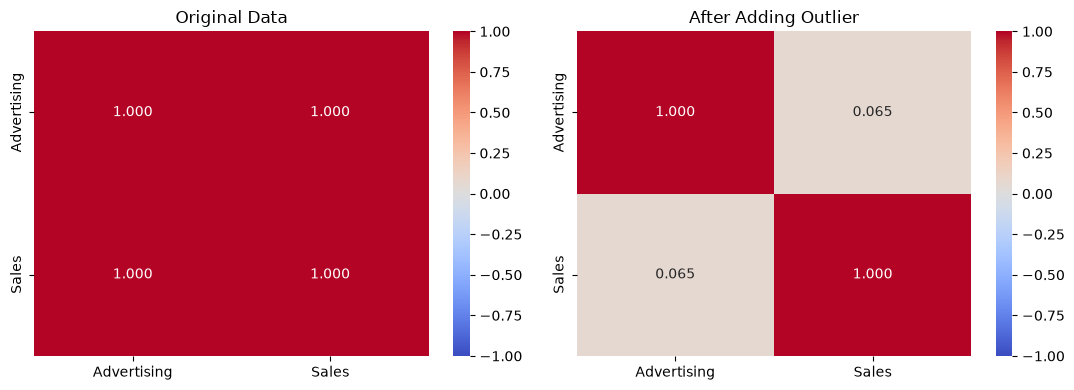

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Advertising": [10, 15, 20, 25, 30, 35, 40, 45, 50, 55],
    "Sales": [20, 28, 35, 42, 50, 58, 65, 72, 80, 88]
})

corr1 = df.corr()
print("Original Correlation Matrix:")
print(corr1.round(3))

new_row = pd.DataFrame({
    "Advertising": [100],
    "Sales": [10]
})

df_new = pd.concat([df, new_row], ignore_index=True)

corr2 = df_new.corr()
print("\nUpdated Correlation Matrix:")
print(corr2.round(3))

before = corr1.loc["Advertising", "Sales"]
after = corr2.loc["Advertising", "Sales"]

print("\nOriginal correlation:", round(before, 4))
print("Updated correlation:", round(after, 4))
print("Change in correlation:", round(after - before, 4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.heatmap(corr1, annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, fmt=".3f", ax=axes[0])
axes[0].set_title("Original Data")

sns.heatmap(corr2, annot=True, cmap="coolwarm",
            vmin=-1, vmax=1, fmt=".3f", ax=axes[1])
axes[1].set_title("After Adding Outlier")

plt.tight_layout()
plt.show()




(b) Write Python code to flag potential outliers and compare the correlation before and after adding the unusual observation. Explain why an extreme point can distort the apparent relationship and why it should be investigated before being removed.

Original Data Outliers

Column: Advertising
Lower Bound: -12.5
Upper Bound: 77.5
Potential Outliers:
Empty DataFrame
Columns: [Advertising, Sales]
Index: []

Column: Sales
Lower Bound: -13.5
Upper Bound: 120.5
Potential Outliers:
Empty DataFrame
Columns: [Advertising, Sales]
Index: []

Updated Data Outliers

Column: Advertising
Lower Bound: -15.0
Upper Bound: 85.0
Potential Outliers:
    Advertising  Sales
10          100     10

Column: Sales
Lower Bound: -24.0
Upper Bound: 124.0
Potential Outliers:
Empty DataFrame
Columns: [Advertising, Sales]
Index: []

Correlation Before: 0.9999
Correlation After: 0.0647
Absolute Change: 0.9352


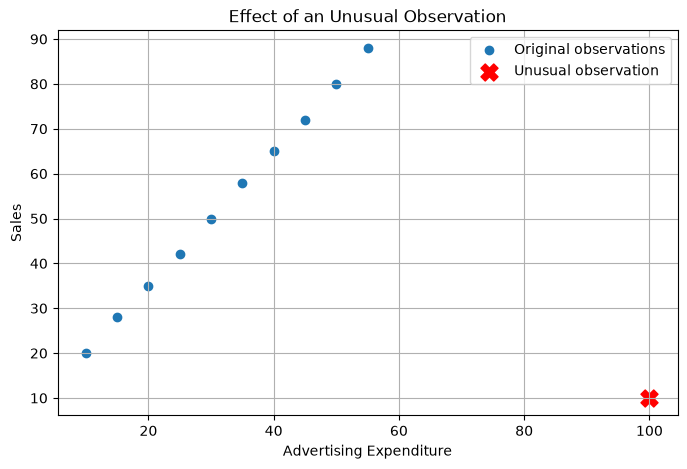

In [12]:
def find_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = data[
        (data[column] < lower) |
        (data[column] > upper)
    ]

    print("\nColumn:", column)
    print("Lower Bound:", round(lower, 2))
    print("Upper Bound:", round(upper, 2))
    print("Potential Outliers:")
    print(outliers)

print("Original Data Outliers")
find_outliers(df, "Advertising")
find_outliers(df, "Sales")

print("\nUpdated Data Outliers")
find_outliers(df_new, "Advertising")
find_outliers(df_new, "Sales")

print("\nCorrelation Before:", round(before, 4))
print("Correlation After:", round(after, 4))
print("Absolute Change:", round(abs(after - before), 4))

plt.figure(figsize=(8, 5))

plt.scatter(df["Advertising"], df["Sales"],
            label="Original observations")

plt.scatter(100, 10, color="red", marker="X",
            s=150, label="Unusual observation")

plt.xlabel("Advertising Expenditure")
plt.ylabel("Sales")
plt.title("Effect of an Unusual Observation")
plt.legend()
plt.grid(True)
plt.show()
